# 03 — Recorte territorial del Tunari y grilla UTM de 1 km

## Objetivo

Este notebook reemplaza el rectángulo provisional por un **polígono abierto de referencia** del Parque Nacional Tunari y asigna cada detección a una celda fija de 1 km.

La idea esencial es:

1. Leer el archivo armonizado de Bolivia.
2. Aplicar el filtro de calidad ya definido.
3. Conservar solamente puntos dentro del polígono del parque.
4. Proyectar las coordenadas a **UTM 20 Sur (EPSG:32720)**, donde las distancias están en metros.
5. Asignar una celda de 1 km usando un origen fijo derivado del límite territorial.

> **Advertencia:** el límite del parque procede de OpenStreetMap/Nominatim y los distritos de una capa abierta. Son referencias reproducibles, no cartografía oficial. Para un producto institucional deben reemplazarse por capas oficiales de SERNAP y del GAM Cochabamba.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
SERIES = ROOT / "DATOS_PROCESADOS" / "series"
FIGURES = ROOT / "DATOS_PROCESADOS" / "figuras"

In [2]:
from pipeline_tunari_avanzado import preparar_recorte_y_grilla

datos = preparar_recorte_y_grilla()
print(f"Detecciones dentro del polígono: {len(datos):,}")
print(f"Celdas de 1 km con alguna detección: {datos['cell_id_1km'].nunique():,}")
display(datos.groupby(['familia_calibracion', 'platform']).size().rename('detecciones').reset_index())

Detecciones dentro del polígono: 5,646
Celdas de 1 km con alguna detección: 1,728


,familia_calibracion,platform,detecciones
0,MODIS_TERRA_AQUA,Aqua,537
1,MODIS_TERRA_AQUA,Terra,259
2,OTRA,NOAA-21,196
3,VIIRS_NOAA20,NOAA-20,1935
4,VIIRS_SNPP,Suomi-NPP,2719


## Por qué UTM y no grados

Un grado de longitud no representa la misma distancia en todos los lugares. En UTM, `x_utm_m` y `y_utm_m` están en metros; por eso una cuadrícula de 1.000 × 1.000 m es realmente comparable en todo el parque.

`cell_id_1km` es determinista: si volvemos a ejecutar el análisis con más años, una coordenada caerá en la misma celda.

In [3]:
meta = json.loads((ROOT / 'DATOS_PROCESADOS/geografia/metadatos_grilla_1km.json').read_text(encoding='utf-8'))
display(pd.Series(meta, name='valor').to_frame())
display(pd.read_csv(ROOT / 'DATOS_PROCESADOS/geografia/fuentes_geograficas.csv'))

,valor
fuente_datos,firms_bolivia_armonizado_con_2026.parquet
cobertura_hasta,2026-10-31
crs_geografico,EPSG:4326
crs_grilla,EPSG:32720
tamano_celda_m,1000.0
origen_x_m,102000.0
origen_y_m,8055000.0
regla_columna,floor((x_utm_m - origen_x_m) / 1000)
regla_fila,floor((y_utm_m - origen_y_m) / 1000)
filas_bbox_antes_de_filtros,12811


,capa,fuente,url,licencia,es_oficial,fecha_descarga,limitacion
0,parque_tunari_referencia_osm.geojson,OpenStreetMap contributors / Nominatim,https://nominatim.openstreetmap.org/search?q=P...,ODbL 1.0,no,2026-11-11,Geometría abierta de referencia. No sustituye ...
1,distritos_cochabamba_referencia.geojson,Hogaria / ciudatoslab / OpenStreetMap,https://hogaria.com/geo/datos/distritos.geojson,ODbL,no,2026-11-11,Validar con el GAM Cochabamba antes de decisio...
2,referencia_independiente_wdpa,"UNEP-WCMC Protected Planet, WDPA ID 4644",https://www.protectedplanet.net/4644,Términos de Protected Planet,referencia internacional,2026-11-11,La ficha reporta 3288.79 km²; el sitio público...
3,municipios_tunari_referencia.geojson,OpenStreetMap contributors / Overpass,https://overpass-api.de/api/interpreter (relat...,ODbL 1.0,no,2026-11-11,Geometría abierta simplificada (~20 m). Solo m...


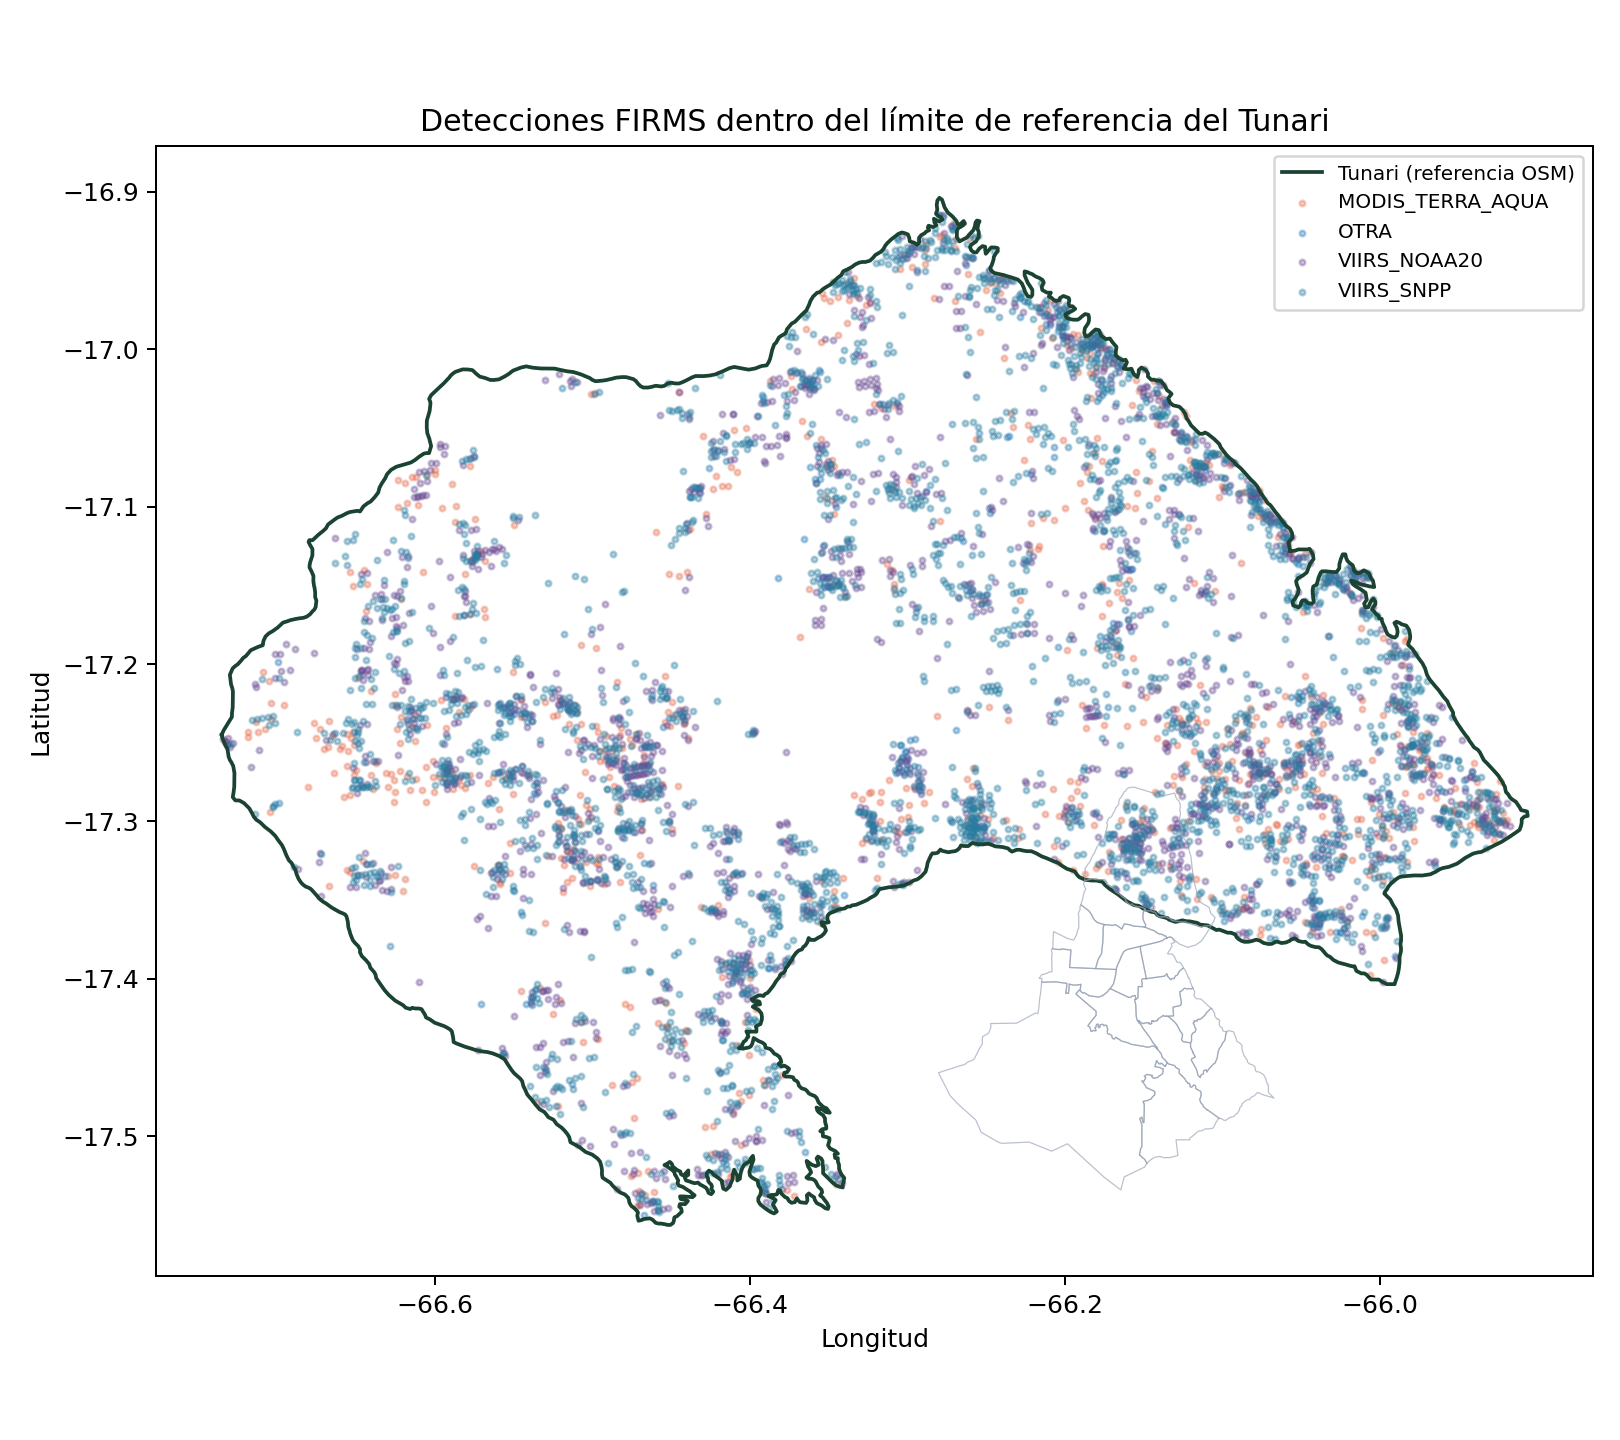

In [4]:
display(Image(filename=str(FIGURES / 'tunari_limite_referencia_y_detecciones.png')))